# 04 - AGEB indicators

Crosses the vegetation map with population (INEGI Censo 2020), social lag (CONEVAL 2020) and surface temperature (Landsat-8) for every urban AGEB of the ZMM. This was originally done in QGIS, the same steps are reproduced here:

1. Vegetation inside each AGEB and within 500 m of it (zonal statistics + buffer).
2. Green per capita and accessible green per capita.
3. Mean surface temperature and difference with the urban mean.
4. Environmental criticality index (density + temperature + lack of access, by quintiles).
5. Priority AGEB: very high criticality and medium or higher social lag.
6. Green Score.

At the end the results are compared with the original QGIS layer.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterstats import zonal_stats

from config import (agebFile,censusFile,conevalFile,lstFile,qgisRefFile,
                    predictionsFolder,processedFolder,resultsFolder)

greenRfPath=predictionsFolder/'GREEN_ZMM_RF.tif'
greenNdviPath=predictionsFolder/'GREEN_ZMM_NDVI03.tif'

projCrs='EPSG:6372'   # Mexico ITRF2008 / LCC, in meters (needed for areas and buffers)

## AGEB, population and social lag

In [2]:
ageb=gpd.read_file(agebFile).to_crs(projCrs)
ageb=ageb[['CVEGEO','AREA_m2','geometry']]
print('Urban AGEB in the ZMM:',len(ageb))

# Censo 2020: the AGEB totals are the rows with MZA = 000 (block 0)
census=pd.read_csv(censusFile,dtype=str,usecols=['ENTIDAD','MUN','LOC','AGEB','MZA','POBTOT'],encoding='utf-8-sig')
census=census[(census['MZA']=='000')&(census['AGEB']!='0000')].copy()
census['CVEGEO']=census['ENTIDAD']+census['MUN']+census['LOC']+census['AGEB']
census['pob_tot']=pd.to_numeric(census['POBTOT'],errors='coerce').fillna(0).astype(int)

# CONEVAL: grade of social lag, from 1 (very low) to 5 (very high)
coneval=pd.read_csv(conevalFile,dtype=str,encoding='utf-8-sig')
coneval=coneval.rename(columns={'Clave de la AGEB':'CVEGEO','Grado de rezago social':'rezago'})
coneval['rezago']=coneval['rezago'].str.strip()
rezagoLevels={'Muy bajo':1,'Bajo':2,'Medio':3,'Alto':4,'Muy alto':5}
coneval['rezago_n']=coneval['rezago'].map(rezagoLevels)

ageb=ageb.merge(census[['CVEGEO','pob_tot']],on='CVEGEO',how='inner')   # AGEB without census data are dropped
ageb=ageb.merge(coneval[['CVEGEO','rezago','rezago_n']],on='CVEGEO',how='left')

print('AGEB with population data:',len(ageb))
print('AGEB without CONEVAL grade:',ageb['rezago_n'].isna().sum())
print('Population:',ageb['pob_tot'].sum())

Urban AGEB in the ZMM: 2229
AGEB with population data: 2155
AGEB without CONEVAL grade: 78
Population: 5245560


## Zonal statistics
For each polygon, share of vegetation pixels (mean of the 0/1 mask). A pixel counts when its center is inside the polygon, as in QGIS.

In [3]:
def zonalMean(polygons,rasterPath,stats=['mean']):
    with rasterio.open(rasterPath) as src:
        rasterCrs=src.crs
        noData=src.nodata if src.nodata is not None else -9999   # LST has no nodata value, its empty pixels are NaN
    zs=zonal_stats(polygons.to_crs(rasterCrs),str(rasterPath),stats=stats,nodata=noData)
    return pd.DataFrame(zs,index=polygons.index)

buffers=ageb.geometry.buffer(500)   # 500 m around each AGEB (includes the AGEB)
buffers=gpd.GeoSeries(buffers,crs=projCrs)

greenIn=zonalMean(ageb.geometry,greenRfPath)
greenBuffer=zonalMean(buffers,greenRfPath)
ndviIn=zonalMean(ageb.geometry,greenNdviPath)
lst=zonalMean(ageb.geometry,lstFile,stats=['mean','max'])

ageb['green_frac']=greenIn['mean'].fillna(0)
ageb['green_frac_buffer']=greenBuffer['mean'].fillna(0)
ageb['area_green_buffer_m2']=ageb['green_frac_buffer']*buffers.area
ageb['green_frac_ndvi']=ndviIn['mean'].fillna(0)
ageb['lst_mean']=lst['mean']
ageb['lst_max']=lst['max']

## Indicators
Same formulas as the QGIS field calculator. It is a function so it can also be applied to the QGIS zonal statistics at the end.

In [4]:
def quintile(x):
    # 1 = lowest 20%, 5 = highest 20%
    return pd.qcut(x,5,labels=False,duplicates='drop').astype(int)+1

def computeIndicators(df):
    df=df.copy()
    hasPop=df['pob_tot']>0
    df['has_pop']=hasPop.astype(int)

    # Green inside the AGEB
    df['pct_green']=100*df['green_frac']
    df['area_green_m2']=df['green_frac']*df['AREA_m2']
    df['dens_pob']=df['pob_tot']/df['AREA_m2']*1e6                                     # inhabitants / km2
    df['green_per_cap']=np.where(hasPop,df['area_green_m2']/df['pob_tot'].where(hasPop,1),0)   # m2 / inhabitant

    # Green within 500 m (access)
    df['pct_green_buffer']=100*df['green_frac_buffer']
    df['access_green']=np.where(hasPop,df['area_green_buffer_m2']/df['pob_tot'].where(hasPop,1),0)

    # Temperature compared with the mean of the populated AGEB
    df['temp_delta']=df['lst_mean']-df.loc[hasPop,'lst_mean'].mean()

    # Environmental criticality: exposure (temperature) + sensitivity (density) + lack of adaptive capacity (access)
    df['access_q']=quintile(df['access_green'])
    df['dens_q']=quintile(df['dens_pob'])
    df['temp_q']=quintile(df['lst_mean'])
    df['crit_amb']=df['dens_q']+df['temp_q']+(6-df['access_q'])
    df['crit_q5']=quintile(df['crit_amb'])
    df['crit_cat']=np.select([df['crit_amb']<=8,df['crit_amb']<=11],[1,2],3)   # 1 medium, 2 high, 3 very high

    # Deficit against 10 m2 per inhabitant
    df['def_green_int']=(10-df['green_per_cap']).clip(lower=0)
    df['def_green_buff']=(10-df['access_green']).clip(lower=0)

    # Priority: very high criticality and social lag medium or higher
    df['priority']=((df['crit_cat']==3)&(df['rezago_n']>=3)).astype(int)
    df['pob_crit']=np.where(df['priority']==1,df['pob_tot'],0)

    # Green Score: coverage (target 30%), green per capita (target 30 m2), access (target 9 m2, double weight)
    df['cov_idx']=(df['pct_green_buffer']/30*100).clip(0,100)
    df['gpc_idx']=(df['green_per_cap']/30*100).clip(0,100)
    df['acc_idx']=(df['access_green']/9*100).clip(0,100)
    df['green_score']=(df['cov_idx']+df['gpc_idx']+2*df['acc_idx'])/4
    return df

ageb=computeIndicators(ageb)

## Results

In [5]:
priority=ageb[ageb['priority']==1]

print('AGEB:',len(ageb))
print('Criticality - medium/high/very high:',ageb['crit_cat'].value_counts().sort_index().tolist())
print('Priority AGEB:',len(priority))
print('Population in priority AGEB:',priority['pob_tot'].sum(),
      f"({100*priority['pob_tot'].sum()/ageb['pob_tot'].sum():.1f}% of the ZMM)")
print('Social lag of the priority AGEB:',priority['rezago'].value_counts().to_dict())
print(f"Median Green Score: {ageb['green_score'].median():.1f}")

AGEB: 2155
Criticality - medium/high/very high: [860, 839, 456]
Priority AGEB: 155
Population in priority AGEB: 599810 (11.4% of the ZMM)
Social lag of the priority AGEB: {'Medio': 153, 'Alto': 2}
Median Green Score: 80.5


Vegetation by AGEB, Random Forest vs NDVI > 0.3 (the comparison made in QGIS)

In [6]:
difPct=100*(ageb['green_frac']-ageb['green_frac_ndvi'])
print(f'Correlation RF vs NDVI by AGEB: {ageb["green_frac"].corr(ageb["green_frac_ndvi"]):.3f}')
print(f'Difference in % of vegetation (RF - NDVI): median {difPct.median():.1f}, 5-95%: {difPct.quantile(0.05):.1f} to {difPct.quantile(0.95):.1f}')

Correlation RF vs NDVI by AGEB: 0.972
Difference in % of vegetation (RF - NDVI): median 0.1, 5-95%: -3.4 to 8.9


Maps

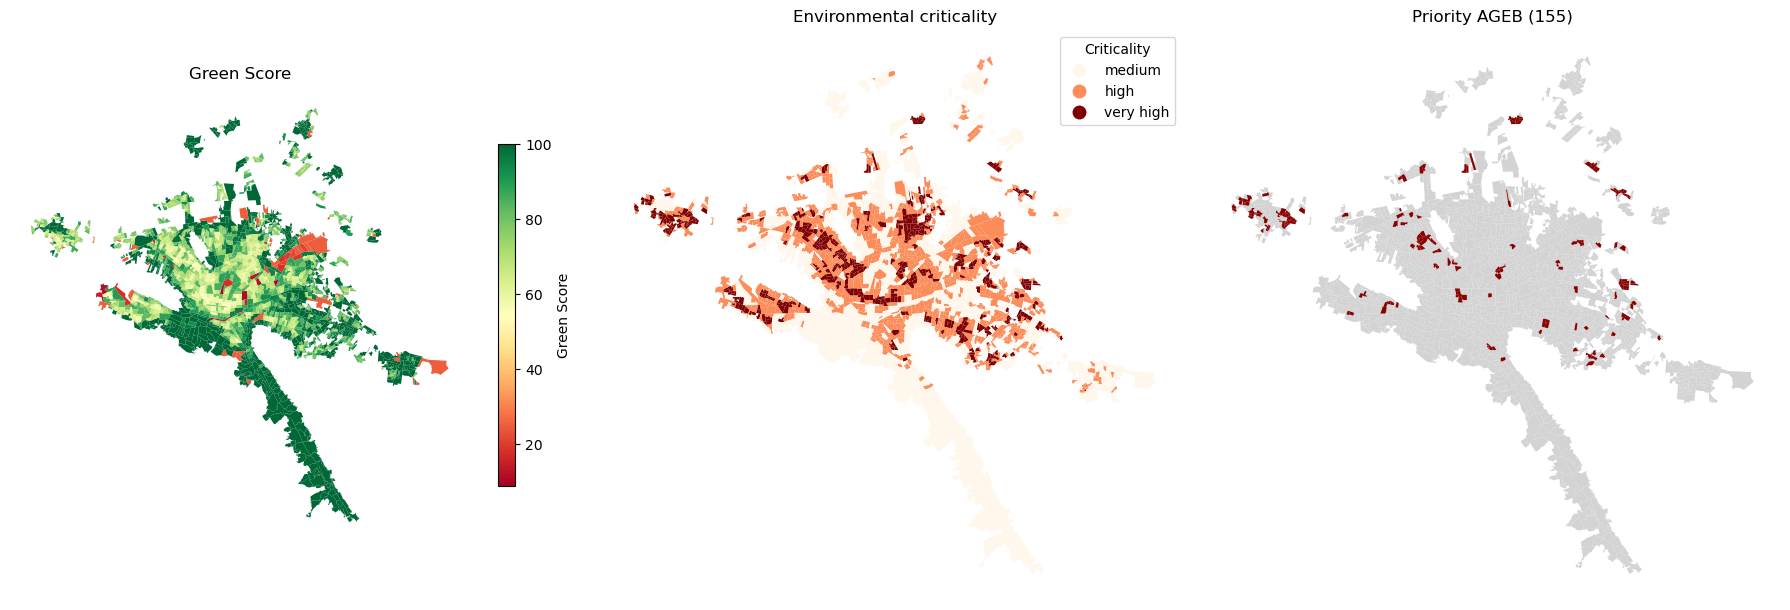

In [7]:
fig,axes=plt.subplots(1,3,figsize=(18,6))

ageb.plot(column='green_score',cmap='RdYlGn',legend=True,ax=axes[0],
          legend_kwds={'shrink':0.6,'label':'Green Score'})
axes[0].set_title('Green Score')

ageb.plot(column='crit_cat',cmap='OrRd',categorical=True,legend=True,ax=axes[1],
          legend_kwds={'labels':['medium','high','very high'],'title':'Criticality'})
axes[1].set_title('Environmental criticality')

ageb.plot(color='lightgray',ax=axes[2])
priority.plot(color='darkred',ax=axes[2])
axes[2].set_title(f'Priority AGEB ({len(priority)})')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(resultsFolder/'ageb_maps.png',dpi=200,bbox_inches='tight')
plt.show()

Save the results. The full layer (with geometry) stays in `data/processed`, the table goes to `results`.

In [8]:
outCols=['CVEGEO','AREA_m2','pob_tot','rezago','rezago_n','pct_green','area_green_m2','dens_pob','green_per_cap',
         'pct_green_buffer','area_green_buffer_m2','access_green','lst_mean','lst_max','temp_delta',
         'access_q','dens_q','temp_q','crit_amb','crit_q5','crit_cat','def_green_int','def_green_buff',
         'priority','pob_crit','cov_idx','gpc_idx','acc_idx','green_score']

ageb[outCols+['geometry']].to_file(processedFolder/'ageb_indicators.gpkg',driver='GPKG')
ageb[outCols].to_csv(resultsFolder/'ageb_indicators.csv',index=False,float_format='%.4f')
priority[outCols].sort_values('pob_tot',ascending=False).to_csv(resultsFolder/'priority_ageb.csv',index=False,float_format='%.4f')

## Comparison with the original QGIS layer
1. **Formulas:** the QGIS zonal statistics are passed through `computeIndicators`. Every column should match QGIS (small differences only where QGIS rounded to 3 decimals).
2. **Full pipeline:** this notebook vs QGIS. Here differences are expected, the vegetation map now comes from a model trained with all the labels and the zonal statistics are computed again.

Note: in the QGIS layer `pob_tot` ended up overwritten with 0/1 (the indicators had already been calculated with the real population), so the population is taken from the census here.

In [9]:
qgis=gpd.read_file(qgisRefFile)
qgis=qgis.drop(columns='pob_tot').merge(census[['CVEGEO','pob_tot']],on='CVEGEO',how='left')

# 1. Formulas
qgisIn=pd.DataFrame({
    'CVEGEO':qgis['CVEGEO'],
    'AREA_m2':qgis['AREA_m2'],
    'pob_tot':qgis['pob_tot'],
    'rezago_n':qgis['rezago_n'],
    'green_frac':qgis['green_sum']/qgis['green_count'],
    'green_frac_buffer':qgis['pct_green_buffer']/100,
    'area_green_buffer_m2':qgis['area_green_buffer_m2'],
    'lst_mean':qgis['lst_mean'],
})
check=computeIndicators(qgisIn)

checkCols=['pct_green','dens_pob','green_per_cap','access_green','temp_delta','access_q','dens_q','temp_q',
           'crit_amb','crit_q5','crit_cat','def_green_int','def_green_buff','cov_idx','gpc_idx','acc_idx','green_score']
formulaCheck=pd.DataFrame({
    'max abs difference':[np.abs(check[c]-qgis[c]).max() for c in checkCols]
},index=checkCols)
formulaCheck['match']=formulaCheck['max abs difference']<0.005
print('Priority AGEB equal to QGIS:',(check['priority']==qgis['pob_crit']).all())
formulaCheck

Priority AGEB equal to QGIS: True


,max abs difference,match
pct_green,1.421085e-14,True
dens_pob,7.275958e-12,True
green_per_cap,5.820766e-11,True
access_green,5.000000e-04,True
temp_delta,1.421085e-14,True
access_q,0.000000e+00,True
dens_q,0.000000e+00,True
temp_q,0.000000e+00,True
crit_amb,0.000000e+00,True
crit_q5,0.000000e+00,True


In [10]:
# 2. Full pipeline
both=ageb.merge(qgis[['CVEGEO','pct_green','pct_green_buffer','access_green','lst_mean','green_score','pob_crit']],
                on='CVEGEO',suffixes=('','_qgis'))

pipelineCheck=pd.DataFrame({
    'correlation':[both[c].corr(both[c+'_qgis']) for c in ['pct_green','pct_green_buffer','access_green','lst_mean','green_score']],
    'median abs difference':[(both[c]-both[c+'_qgis']).abs().median() for c in ['pct_green','pct_green_buffer','access_green','lst_mean','green_score']],
},index=['pct_green','pct_green_buffer','access_green','lst_mean','green_score'])

samePriority=((both['priority']==1)&(both['pob_crit_qgis']==1)).sum()
print(f"Priority AGEB: {both['priority'].sum()} here, {int(both['pob_crit_qgis'].sum())} in QGIS, {samePriority} in both")
pipelineCheck.round(4)

Priority AGEB: 155 here, 174 in QGIS, 152 in both


,correlation,median abs difference
pct_green,0.9797,1.9059
pct_green_buffer,0.9645,3.5816
access_green,0.9850,19.1914
lst_mean,1.0000,0.0000
green_score,0.9749,2.2888
